 # Lesson 13 - Exercises for SVD

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec  # for the subplots

# Exercise 1

Compute the SVD for the matrix M defined below.

In [3]:
M = np.array([[1, 2], [3, 4], [5, 6]])

In [5]:
M = np.array([[1, 2], [3, 4], [5, 6]])
(U, S, Vt) = np.linalg.svd(M, full_matrices=False)
print("U:\n", U)
print("S:\n", S)
print("Vt:\n", Vt)

U:
 [[-0.2298477   0.88346102]
 [-0.52474482  0.24078249]
 [-0.81964194 -0.40189603]]
S:
 [9.52551809 0.51430058]
Vt:
 [[-0.61962948 -0.78489445]
 [-0.78489445  0.61962948]]


# Exercise 2

Check if the matrices U, S and Vt you computed in Exercise 1 reconstruct the original matrix M.
     

In [6]:
assert np.allclose(M, U @ np.diag(S) @ Vt)

# Exercise 3 (SVD for Low-Rank Approximations)

**This exercise has 4 questions at the end!!**

In this exercise we will use SVD to approximate an original image. We will use a drawing of Stravinsky. In the following code we use an
image of this drawing `stravin.jpg` that is available in the downloads.

Like with other images, it is natively a 3D tensor (640 × 430 × 3), but we will convert it to grayscale (2D matrix) for convenience.

1. Convert to floats in 0-1 for calculational purposes
2. Convert to grey scale
3. Plot the image


(597, 463, 3)
(597, 463)


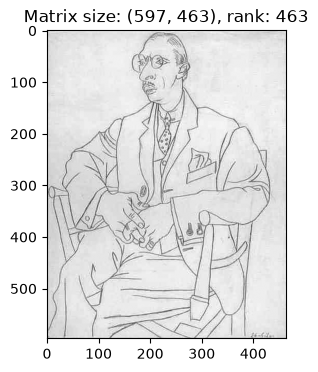

In [7]:
from skimage import io, color

# import picture from directory data and convert values to float between 0-1
strav = io.imread("data/stravin.jpg") / 255
print(strav.shape)
strav = color.rgb2gray(strav)
print(strav.shape)

plt.figure(figsize=(4, 4))# inches
plt.imshow(strav, cmap='gray')
plt.title(f'Matrix size: {strav.shape}, rank: {np.linalg.matrix_rank(strav)}')
plt.show()



In the following code we create a figure containing:

* The original matrix
* A scree plot which is the singular values contribution normalized $\frac{\sigma_i}{\sum_{j=1}^{r}\sigma_j}$. Notice how the first few components account for most of the
contribution of the image, while the later components each account for relatively little
contribution.
* The first twelve “layers”—rank-1 matrices defined as $u_i σ_i v^T_i$  L0, L1, ..., L11
* The cumulative sum of those layers on the bottom row. Ex: L0:3=L0+L1+L2+L3

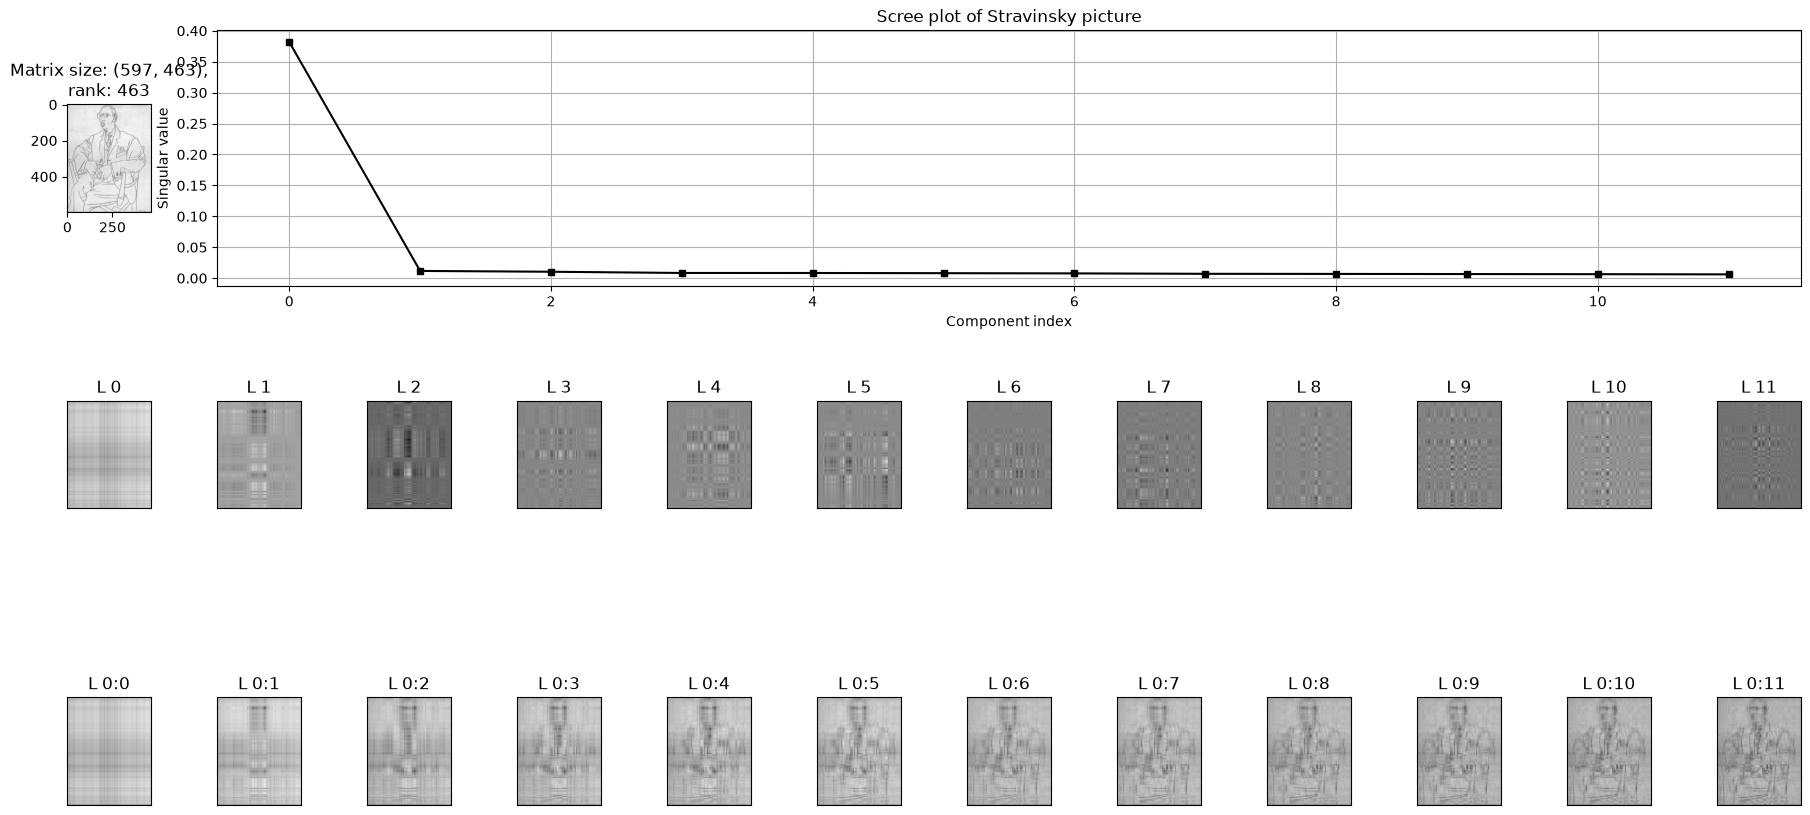

In [14]:
# SVD
U, s, Vt = np.linalg.svd(strav)
S = np.zeros_like(strav)
np.fill_diagonal(S, s)

fig = plt.figure(figsize=(18, 9))
gs = GridSpec(3, 12, figure=fig)

# the image
ax1 = fig.add_subplot(gs[0, 0])
ax1.imshow(strav, cmap='gray')
ax1.set_title(f'Matrix size: {strav.shape},\nrank: {np.linalg.matrix_rank(strav)}')

# scree plot
ax2 = fig.add_subplot(gs[0, 1:])
ax2.plot(s[:12]/sum(s), 'ks-', markersize=5)
ax2.set_xlabel('Component index')
ax2.set_ylabel('Singular value')
ax2.set_title('Scree plot of Stravinsky picture')
ax2.grid()

## now show the first N "layers" separately
numLayers = 12
rank1mats = np.zeros((numLayers, strav.shape[0], strav.shape[1]))

# the loop
for i in range(numLayers):
    # create this layer
    rank1mats[i, :, :] = np.outer(U[:, i], Vt[i, :]) * s[i]

    # show this layer
    ax = fig.add_subplot(gs[1, i])
    ax.imshow(rank1mats[i, :, :], cmap='gray')
    ax.set_title(f'L {i}')
    ax.set_xticks([]), ax.set_yticks([])

    # show the cumulative sum of layers
    ax = fig.add_subplot(gs[2, i])
    ax.imshow(np.sum(rank1mats[:i + 1, :, :], axis=0), cmap='gray')
    ax.set_title(f'L 0:{i}')
    ax.set_xticks([]), ax.set_yticks([])

plt.tight_layout()
plt.show()


You can see that each layer adds more information to the matrix.

Test your knowledge by answering the following questions:

1. What is the relation between the points in the scree plot and the rank-1 matrices $L_i$ ? Ex. relation between the first point and L0?
2. What is the relation between the cumulative sum of layers and the original figure? Ex. Relation between L0:5 and the matrix.
3. What will happen if we continue adding layers. For example what do you expect to happen at L0:40?
4. What is the maximum number of points that we can plot in the scree plot?



1. The scree plot are the relative singular values if we multiply by the sum of all singular values we get the absolute singular value. And this singular value together with the corresponding column of $U$ and row of $V^T$ reconstructs the singular value contribution to the image
2. The cumulative sum adds more and more singgular value contributions So L0:5 is the first 6 singular values contribution(if 0 is the first value)
3. Continuing adding layers will approximate the original better and better if all are used the reconstruction is exact
4. The max numbers of points is the rank of the linear map represented by the matrix

# Exercise 4

Create your own figure for the scree plot making sure it contains all the possible values

<Figure size 1800x900 with 0 Axes>

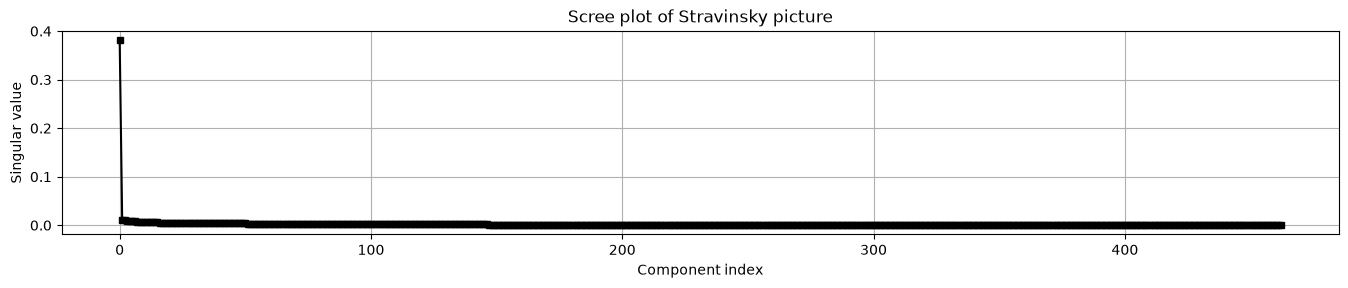

In [19]:
fig = plt.figure(figsize=(18, 9))
gs = GridSpec(3, 12, figure=fig)

# the image

fig = plt.figure(figsize=(18, 9))
gs = GridSpec(3, 12, figure=fig)

# scree plot
ax2 = fig.add_subplot(gs[0, 1:])
ax2.plot(s[:]/sum(s), 'ks-', markersize=5)
ax2.set_xlabel('Component index')
ax2.set_ylabel('Singular value')
ax2.set_title('Scree plot of Stravinsky picture')
ax2.grid()

# Exercise 5

1. Change your scree plot to show only the last 10 points.
2. What can you say about the influence of such values in the reconstruction result?
3. Create your own L 429 matrix
4. Print L 429

<Figure size 1800x900 with 0 Axes>

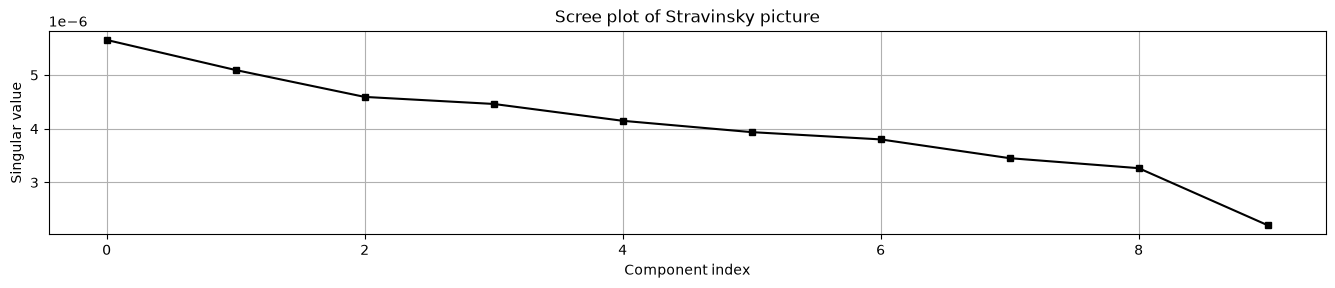

In [20]:
#1.
fig = plt.figure(figsize=(18, 9))
gs = GridSpec(3, 12, figure=fig)

# the image

fig = plt.figure(figsize=(18, 9))
gs = GridSpec(3, 12, figure=fig)

# scree plot
ax2 = fig.add_subplot(gs[0, 1:])
ax2.plot(s[-10:]/sum(s), 'ks-', markersize=5)
ax2.set_xlabel('Component index')
ax2.set_ylabel('Singular value')
ax2.set_title('Scree plot of Stravinsky picture')
ax2.grid()

2. Very low in contribution

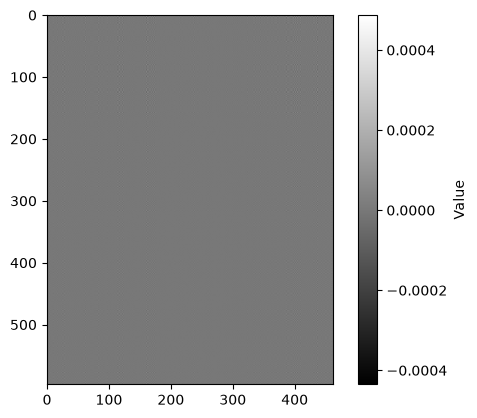

In [24]:
U, s, Vt = np.linalg.svd(strav)

Res = (s[429] * U[:, 429, None]) @ Vt[429, None, :]
plt.imshow(Res, cmap="gray", origin="upper")
plt.colorbar(label="Value")
plt.show()

# Exercise 6

In Exercise 3,  the rank-8 approximation is terrible as a reconstruction of the Stravinsky drawing. It looks nothing like the original image.
The goal of this exercise is to reconstruct the image using more layers so that the low-rank approximation is reasonably accurate—and then compute the amount of
compression obtained.

Start by producing the next figure, which shows the original image, the reconstructed
image, and the error map, which is the squared difference between the original and
the approximation. For this figure, I chose k = 80 components, but I encourage you to
explore different values (that is, different rank approximations).

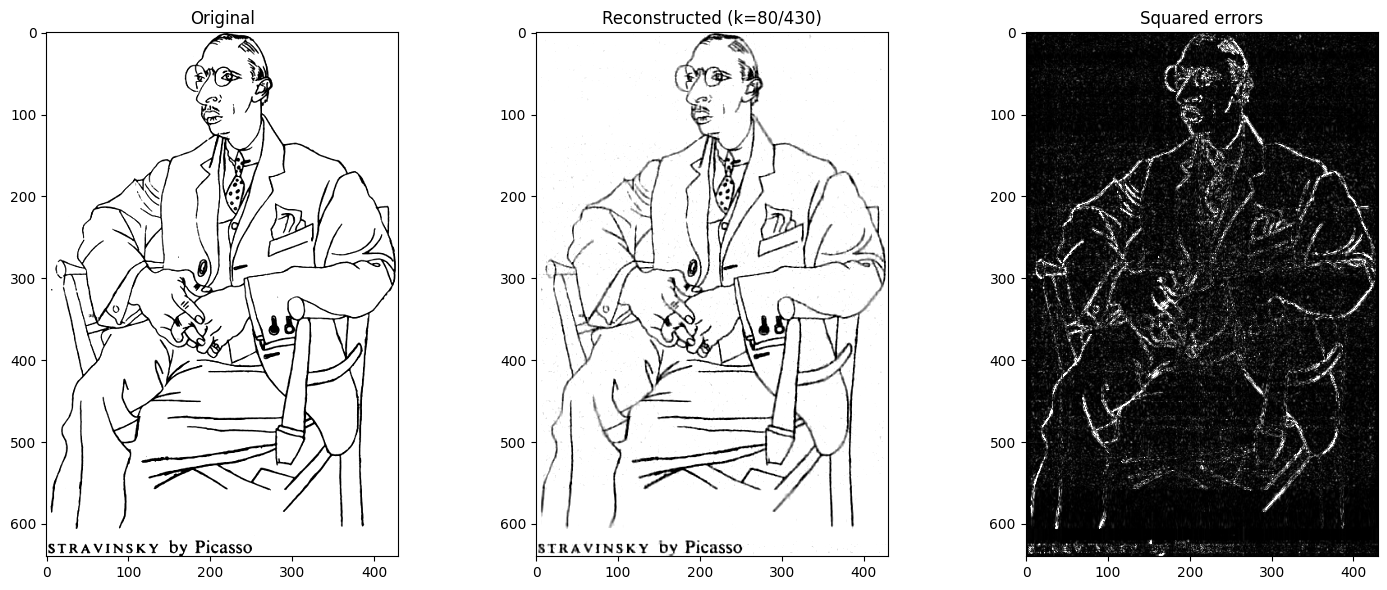

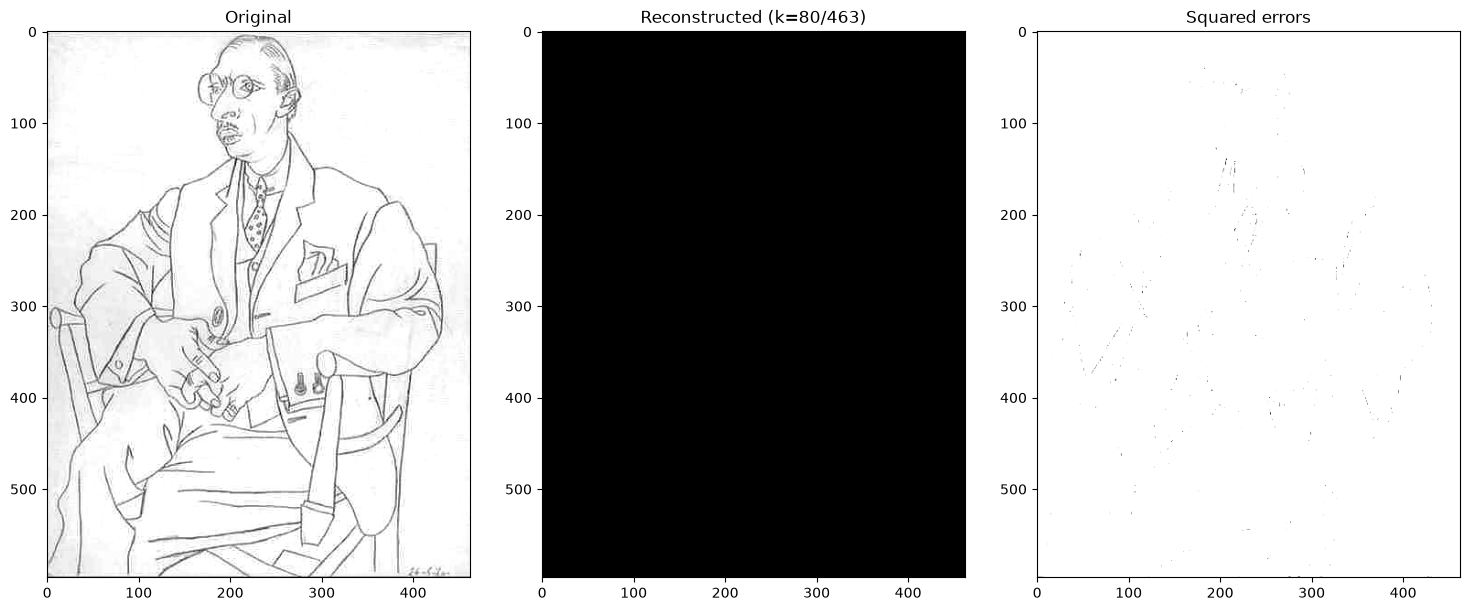

In [25]:


# Reconstruct based on first k layers

# number of components
k = 80

# reconstruction
stravRec = U[:, :k] @ S[:k, :k] @ Vt[:k, :]

# show the original, reconstructed, and error
_, axs = plt.subplots(1, 3, figsize=(15, 6))

axs[0].imshow(strav, cmap='gray', vmin=.1, vmax=.9)
axs[0].set_title('Original')

axs[1].imshow(stravRec, cmap='gray', vmin=.1, vmax=.9)
axs[1].set_title(f'Reconstructed (k={k}/{len(s)})')

axs[2].imshow((strav - stravRec) ** 2, cmap='gray', vmin=0, vmax=1e-1)
axs[2].set_title('Squared errors')

plt.tight_layout()
plt.savefig('Figure_15_10.png', dpi=300)
plt.show()



# Exercise 9

Assuming that $S = A^T A$ and that the SVD of S is $U \Sigma V^T$.

Show that $U \Sigma V^T = V \Sigma U^T$.  

Hint: Use the fact that $S = S^T$.


Use $(AB)^T=B^TA^T$